# 07 · Calidad de los datos de silver

**Propósito:** verificar con reglas medibles que silver es confiable antes de construir las features. Cada regla
informa cuántas filas la incumplen, el porcentaje que cumple, el umbral aceptado y si pasa. Las reglas **críticas**
detienen el notebook con un error si no se cumplen: si fallan, no se debe seguir al notebook 08.

**Entrada:** `silver/vuelos`, `silver/metar_obs` y `silver/clima_horario`, más los conteos de limpieza del
notebook 05 (`docs/evidencias/silver/conteos_vuelos.csv`).

**Salida:** `docs/evidencias/calidad/reporte_calidad.csv` y `.json`, el gráfico `completitud_vuelos.png` y el
historial de ejecuciones en `silver/_calidad/`.

**Requisito:** notebooks 05 y 06.

In [1]:
import os
from pathlib import Path

import yaml

# Carpeta del repositorio (este notebook está en notebooks/)
RAIZ = Path.cwd().parent
with open(RAIZ / "config" / "pipeline.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)
tablas = cfg["lake"]["tablas"]

# En la EC2 la variable LAKE_BUCKET trae el nombre del bucket; en una laptop se trabaja sobre data/lake
BUCKET = os.environ.get("LAKE_BUCKET", "").strip()
RAIZ_LOCAL = RAIZ / cfg["lake"]["raiz_local"]
BASE = f"s3a://{BUCKET}" if BUCKET else RAIZ_LOCAL.resolve().as_uri()


def ruta(tabla: str) -> str:
    """Ruta completa de una tabla declarada en config/pipeline.yaml."""
    return f"{BASE}/{tablas[tabla]}"


def meses(desde: str, hasta: str) -> list[tuple[int, int]]:
    """Pares (año, mes) entre dos fechas AAAA-MM, ambas incluidas."""
    anio, mes = map(int, desde.split("-"))
    anio_fin, mes_fin = map(int, hasta.split("-"))
    salida = []
    while (anio, mes) <= (anio_fin, mes_fin):
        salida.append((anio, mes))
        anio, mes = (anio + 1, 1) if mes == 12 else (anio, mes + 1)
    return salida


DESDE, HASTA = cfg["periodo"]["inicio"], cfg["periodo"]["fin"]
print("Destino:", f"s3://{BUCKET}" if BUCKET else "data/lake (local)")
print("Periodo:", DESDE, "a", HASTA)

Destino: s3://latam-bigdata-lake-728fd64c
Periodo: 2023-01 a 2025-12


In [2]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import types as T
from pyspark.sql.window import Window
import json
from datetime import UTC, datetime

import pandas as pd

# En la EC2 Spark toma la configuración del clúster (spark-defaults.conf); en una laptop corre en modo local
constructor = SparkSession.builder.appName("latam-bigdata-calidad")
if not BUCKET:
    constructor = (
        constructor.master("local[*]")
        .config("spark.sql.shuffle.partitions", str(cfg["spark"]["particiones_shuffle_local"]))
        .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "3g"))
    )
spark = (
    constructor.config("spark.sql.session.timeZone", "UTC")
    .config("spark.sql.sources.partitionOverwriteMode", "dynamic")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")


def en_periodo(df, col_anio="year", col_mes="month"):
    """Deja solo las filas cuyo año y mes están dentro del periodo de config/pipeline.yaml."""
    ym = F.format_string("%04d-%02d", F.col(col_anio), F.col(col_mes))
    return df.where((ym >= DESDE) & (ym <= HASTA))

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/25 08:09:08 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/25 08:09:08 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in mesos/standalone/kubernetes and LOCAL_DIRS in YARN).


26/11/25 08:09:10 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties


26/11/25 08:09:12 WARN S3ABlockOutputStream: Application invoked the Syncable API against stream writing to logs/spark-events/app-20261125080909-0004.inprogress. This is unsupported


In [3]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Paleta: una serie principal en azul; segunda y tercera en naranja y aqua; lo que no se destaca, en gris
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#c9c8c2"
TINTA, TINTA2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e7e6e1", "#fcfcfb"
matplotlib.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "figure.dpi": 110, "legend.frameon": False,
})

In [4]:
EVID = RAIZ / "docs" / "evidencias" / "calidad"
EVID.mkdir(parents=True, exist_ok=True)

vuelos = en_periodo(spark.read.parquet(ruta("silver_vuelos"))).cache()
metar_obs = spark.read.parquet(ruta("silver_metar"))
clima_horario = spark.read.parquet(ruta("silver_clima_horario"))
total_vuelos = vuelos.count()
print(f"Vuelos en silver: {total_vuelos:,}")

reglas = []


def regla(codigo, descripcion, tabla, incumplen, total, umbral_pct, critica):
    """Registra una regla: el porcentaje que cumple debe ser mayor o igual al umbral."""
    pct = round(100 * (1 - incumplen / total), 3) if total else 0.0
    reglas.append({
        "regla": codigo, "descripcion": descripcion, "tabla": tabla, "incumplen": int(incumplen),
        "total": int(total), "pct_cumple": pct, "umbral_pct": umbral_pct, "critica": critica,
        "cumple": pct >= umbral_pct,
    })
    estado = "OK" if pct >= umbral_pct else ("ERROR" if critica else "AVISO")
    print(f"{codigo} [{estado}] {descripcion}: {pct}% (umbral {umbral_pct}%)")

Vuelos en silver: 23,626,998


## 1. Reglas sobre los vuelos

In [5]:
CLAVES = ["id_vuelo", "pais", "aerolinea", "numero_vuelo", "origen", "destino", "salida_prog_utc"]
incompletos = vuelos.where(" OR ".join(f"{c} IS NULL" for c in CLAVES)).count()
regla("Q1", "Campos clave completos", "silver/vuelos", incompletos, total_vuelos, 100.0, True)

duplicados = total_vuelos - vuelos.select("id_vuelo").distinct().count()
regla("Q2", "Sin vuelos duplicados por clave natural", "silver/vuelos", duplicados, total_vuelos, 100.0, True)

operados = vuelos.where(~F.col("cancelado"))
n_operados = operados.count()
regla("Q3", "Vuelos operados con salida real informada", "silver/vuelos",
      operados.where(F.col("salida_real_utc").isNull()).count(), n_operados, 98.0, False)

regla("Q4", "Demora de salida dentro de [-60, 1440] min", "silver/vuelos",
      vuelos.where(F.col("es_atipico")).count(), total_vuelos, 99.0, False)

regla("Q5", "Salida real no anterior en más de 60 min a la programada", "silver/vuelos",
      operados.where(F.col("salida_real_utc") < F.col("salida_prog_utc") - F.expr("INTERVAL 60 MINUTES")).count(),
      n_operados, 99.0, False)

regla("Q6", "Llegada programada posterior a la salida programada", "silver/vuelos",
      vuelos.where(F.col("llegada_prog_utc") <= F.col("salida_prog_utc")).count(), total_vuelos, 99.5, False)

ym = F.format_string("%04d-%02d", F.year("fecha_local"), F.month("fecha_local"))
fuera = spark.read.parquet(ruta("silver_vuelos")).where((ym < DESDE) | (ym > HASTA)).count()
regla("Q7", "Fechas dentro del periodo configurado", "silver/vuelos", fuera, total_vuelos + fuera, 100.0, True)

no_desviados = operados.where(~F.col("desviado"))
regla("Q8", "Vuelos operados con etiqueta de demora", "silver/vuelos",
      no_desviados.where(F.col("y_demora15").isNull()).count(), no_desviados.count(), 98.0, False)

Q1 [OK] Campos clave completos: 100.0% (umbral 100.0%)


Q2 [OK] Sin vuelos duplicados por clave natural: 100.0% (umbral 100.0%)


Q3 [OK] Vuelos operados con salida real informada: 100.0% (umbral 98.0%)


Q4 [OK] Demora de salida dentro de [-60, 1440] min: 99.966% (umbral 99.0%)


Q5 [OK] Salida real no anterior en más de 60 min a la programada: 99.976% (umbral 99.0%)


Q6 [OK] Llegada programada posterior a la salida programada: 99.999% (umbral 99.5%)


Q7 [OK] Fechas dentro del periodo configurado: 100.0% (umbral 100.0%)


Q8 [OK] Vuelos operados con etiqueta de demora: 100.0% (umbral 98.0%)


## 2. Reglas sobre el clima

- **Q9:** la cobertura de clima se mide como lo usará el modelo: para cada vuelo operado, ¿hay clima del origen en
  la hora `k` = salida programada − 2 h?
- **Q10:** qué porcentaje de los METAR se pudo leer (viento y visibilidad).
- **Q11:** vuelos de EE. UU. descartados en el notebook 05 por no tener zona horaria.

In [6]:
k_ref = F.date_trunc("hour", F.col("salida_prog_utc") - F.expr("INTERVAL 2 HOURS"))
con_clima = (
    operados.select("pais", F.col("origen").alias("aeropuerto"), k_ref.alias("k"))
    .join(clima_horario.select("aeropuerto", "k", F.lit(1).alias("hay")), ["aeropuerto", "k"], "left")
    .groupBy("pais").agg(F.count("*").alias("vuelos"), F.sum(F.coalesce("hay", F.lit(0))).alias("con_clima"))
    .toPandas().set_index("pais")
)
display(con_clima.assign(pct=lambda d: (100 * d.con_clima / d.vuelos).round(2)))
for pais, fila in con_clima.iterrows():
    regla(f"Q9-{pais}", f"Vuelos de {pais} con clima del origen a T-2 h", "silver/clima_horario",
          fila.vuelos - fila.con_clima, fila.vuelos, 90.0, False)

n_metar = metar_obs.count()
regla("Q10", "METAR con viento y visibilidad decodificados", "silver/metar_obs",
      metar_obs.where(F.col("viento_kt").isNull() | F.col("visibilidad_m").isNull()).count(), n_metar, 95.0, False)

archivo_conteos = RAIZ / "docs" / "evidencias" / "silver" / "conteos_vuelos.csv"
if archivo_conteos.exists():
    conteos = pd.read_csv(archivo_conteos).set_index("pais")
    if "US" in conteos.index:
        regla("Q11", "Vuelos de EE. UU. con zona horaria del aeropuerto", "bronze/bts",
              conteos.loc["US", "sin_zona_horaria"], conteos.loc["US", "leidas"], 99.0, False)
else:
    print("Q11 no se evaluó: falta docs/evidencias/silver/conteos_vuelos.csv (se genera en el notebook 05)")

,vuelos,con_clima,pct
pais,,,
BR,2760182,2619634,94.91
US,20461598,20161543,98.53


Q9-BR [OK] Vuelos de BR con clima del origen a T-2 h: 94.908% (umbral 90.0%)
Q9-US [OK] Vuelos de US con clima del origen a T-2 h: 98.534% (umbral 90.0%)


Q10 [OK] METAR con viento y visibilidad decodificados: 99.395% (umbral 95.0%)
Q11 [OK] Vuelos de EE. UU. con zona horaria del aeropuerto: 99.133% (umbral 99.0%)


## 3. Completitud por campo

Porcentaje de filas con dato en cada campo de `silver/vuelos`, por país. Las horas reales y las demoras faltan, por
diseño, en los vuelos cancelados.

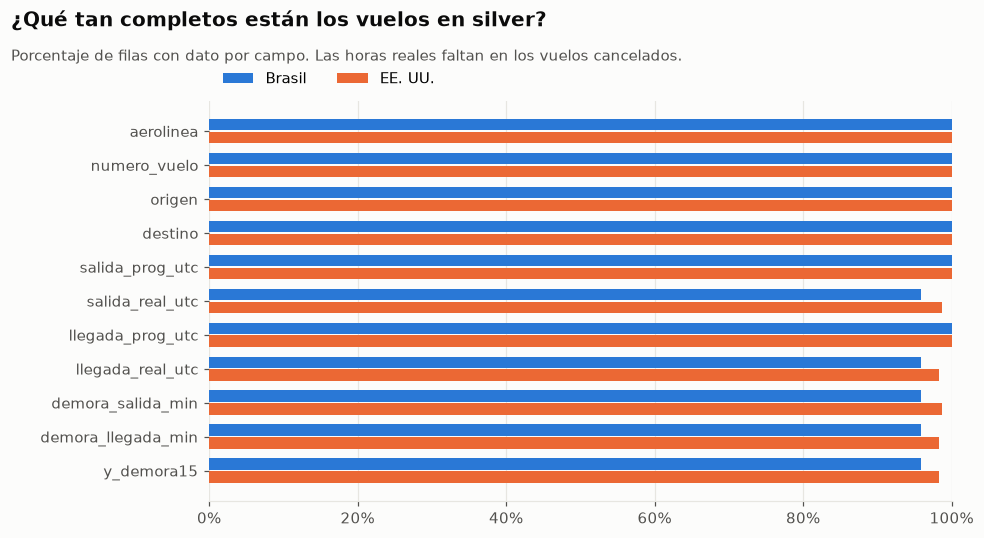

In [7]:
CAMPOS = [
    "aerolinea", "numero_vuelo", "origen", "destino", "salida_prog_utc", "salida_real_utc", "llegada_prog_utc",
    "llegada_real_utc", "demora_salida_min", "demora_llegada_min", "y_demora15",
]
completitud = (
    vuelos.groupBy("pais").agg(*[F.round(100 * F.count(c) / F.count("*"), 2).alias(c) for c in CAMPOS])
    .toPandas().set_index("pais").T
)
completitud.to_csv(EVID / "completitud_vuelos.csv", index_label="campo")

fig, ax = plt.subplots(figsize=(9, 5.2))
fig.subplots_adjust(left=0.22, right=0.97, top=0.82, bottom=0.12)
alto = 0.38
for i, (pais, color) in enumerate([("BR", AZUL), ("US", NARANJA)]):
    if pais in completitud.columns:
        y = [k + (i - 0.5) * alto for k in range(len(CAMPOS))]
        ax.barh(y, completitud[pais], height=alto - 0.04, color=color, label={"BR": "Brasil", "US": "EE. UU."}[pais])
ax.set_yticks(range(len(CAMPOS)), CAMPOS)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
fig.text(0.02, 0.95, "¿Qué tan completos están los vuelos en silver?", fontsize=13, fontweight="bold", color=TINTA)
fig.text(0.02, 0.89, "Porcentaje de filas con dato por campo. Las horas reales faltan en los vuelos cancelados.",
         fontsize=10, color=TINTA2)
fig.savefig(EVID / "completitud_vuelos.png", dpi=160)
plt.show()

## 4. Reporte

In [8]:
reporte = pd.DataFrame(reglas)
ejecucion = datetime.now(UTC).isoformat(timespec="seconds")
reporte.to_csv(EVID / "reporte_calidad.csv", index=False)
(EVID / "reporte_calidad.json").write_text(
    json.dumps({"ejecucion_utc": ejecucion, "periodo": [DESDE, HASTA], "reglas": reglas}, ensure_ascii=False,
               indent=2, default=bool),
    encoding="utf-8",
)
# Historial en el lake: una fila por regla y ejecución
(
    spark.createDataFrame(reporte.astype({"cumple": bool, "critica": bool}))
    .withColumn("ejecucion_utc", F.lit(ejecucion))
    .write.mode("append").parquet(ruta("silver_calidad"))
)
reporte

,regla,descripcion,tabla,incumplen,total,pct_cumple,umbral_pct,critica,cumple
0,Q1,Campos clave completos,silver/vuelos,0,23626998,100.000,100.0,True,True
1,Q2,Sin vuelos duplicados por clave natural,silver/vuelos,0,23626998,100.000,100.0,True,True
2,Q3,Vuelos operados con salida real informada,silver/vuelos,0,23221780,100.000,98.0,False,True
3,Q4,"Demora de salida dentro de [-60, 1440] min",silver/vuelos,8100,23626998,99.966,99.0,False,True
4,Q5,Salida real no anterior en más de 60 min a la ...,silver/vuelos,5673,23221780,99.976,99.0,False,True
5,Q6,Llegada programada posterior a la salida progr...,silver/vuelos,342,23626998,99.999,99.5,False,True
6,Q7,Fechas dentro del periodo configurado,silver/vuelos,0,23626998,100.000,100.0,True,True
7,Q8,Vuelos operados con etiqueta de demora,silver/vuelos,0,23168971,100.000,98.0,False,True
8,Q9-BR,Vuelos de BR con clima del origen a T-2 h,silver/clima_horario,140548,2760182,94.908,90.0,False,True
9,Q9-US,Vuelos de US con clima del origen a T-2 h,silver/clima_horario,300055,20461598,98.534,90.0,False,True


In [9]:
criticas_fallidas = reporte[reporte.critica & ~reporte.cumple]
assert criticas_fallidas.empty, f"Reglas críticas incumplidas: {criticas_fallidas.regla.tolist()}"
print("Todas las reglas críticas se cumplen.")

Todas las reglas críticas se cumplen.


In [10]:
spark.stop()